In [1]:
import pandas as pd
import numpy as np

import sympy as sp

from sympy import exp, sin
import time
from dataclasses import dataclass

from numpy import array

from utils import get_fitted_scaler_from_csv, scale_dataframe, clean_point, get_scaled, symbolic_gradient, get_distances_and_features_ckdtree, mean_absolute_error_numpy, COLUMN_TO_VAR


# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col)




# Define the dataclass
@dataclass
class DataPoint:
    '''
    Point is in the format: 
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    '''
    point: tuple
    index: int
    temp_class: str
    gibbs_energy: float = None
    
    


# Load the file
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")


# Scaling the dataframe


# df = scale_dataframe(df, 'Gibbs_energy')

# print(scaled_df.head)

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(scaled_df) * 0.8)

# Randomly sample 80% of the rows
reference_df = scaled_df.sample(n=sample_size, random_state=42)

# print(reference_df.head)



# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]
# print(reference_df.head)

ref_gibbs = np.array(reference_df['Gibbs_energy'])

reference_df_rename = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# print(reference_df_rename.shape)
# print(reference_df_rename.head)
# Create a list of DataPoint instances
# print(reference_df)
df_reset_ref = reference_df_rename.reset_index(drop=True)
# print(reference_df_rename.shape)
# print(df_reset_ref.head)
# df_reset_ref = df_reset_ref.drop(df_reset_ref.columns[0], axis=1)
# Convert the DataFrame to a NumPy array
ref_points = np.array([clean_point(point) for point in df_reset_ref.values])



scaled_ref_data_points = []
for idx, row in reference_df_rename.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    scaled_point = np.array(clean_point(point))
    scaled_ref_data_points.append(DataPoint(point=scaled_point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))

sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = scaled_df.drop(sampled_indices)

test_gibbs = np.array(remaining_df['Gibbs_energy'])

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

# print(remaining_df.head)

# print(remaining_df.head)



df_reset = remaining_df.reset_index(drop=True)
# df_reset = df_reset.drop(df_reset.columns[0], axis=1)
# Convert the DataFrame to a NumPy array
query_points = np.array([clean_point(point) for point in df_reset.values])

# # Create a list of DataPoint instances for the remaining 20%
scaled_remaining_data_points = []
for idx, row in remaining_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    scaled_point = np.array(clean_point(point))

    scaled_remaining_data_points.append(DataPoint(point=scaled_point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))
    


/home/couchbucks/Documents/saketh/regression/regression/utils.py:157: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/tmp/ipykernel_2056308/3722711716.py:51: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [2]:


new_order_gibbs = [
    'Gibbs_energy',
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'temp_class'
    # 'Mass_fraction_Ni'
]

scaled_df_selected = scaled_df[new_order_gibbs]

In [11]:
gibbs_energy = scaled_df_selected[['Gibbs_energy', 'temp_class']]

gibbs_energy

,Gibbs_energy,temp_class
0,1.843888,nb
1,1.807418,nb
2,1.770809,nb
3,1.734061,nb
4,1.697175,nb
...,...,...
8176,-1.344189,cr
8177,-1.390042,cr
8178,-1.435983,cr
8179,-1.482012,cr


In [9]:
from sklearn.decomposition import PCA

In [12]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_df_selected.drop(['Gibbs_energy', 'temp_class'], axis=1))

# Creating a new DataFrame with the PCA results and Gibbs_energy
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
final_df = pd.concat([gibbs_energy, pca_df], axis=1)

final_df

,Gibbs_energy,temp_class,PC1,PC2
0,1.843888,nb,0.515950,0.628470
1,1.807418,nb,0.515950,0.628470
2,1.770809,nb,0.515950,0.628470
3,1.734061,nb,0.515950,0.628470
4,1.697175,nb,0.515950,0.628470
...,...,...,...,...
8176,-1.344189,cr,-0.143888,0.121622
8177,-1.390042,cr,-0.143888,0.121622
8178,-1.435983,cr,-0.143888,0.121622
8179,-1.482012,cr,-0.143888,0.121622


In [ ]:
# Saving final_df as a CSV file with tab as the delimiter
final_df.to_csv('pca_all.csv', sep='\t', index=False)


In [317]:
import os

unique_classes = final_df['temp_class'].unique()

# Process each unique value
for temp_class in unique_classes:
    # Filter DataFrame for the current temp_class
    filtered_df = final_df[final_df['temp_class'] == temp_class]
    
    filtered_df = filtered_df.drop('temp_class', axis=1)
    
    # Define the directory and file path
    directory = f'718_all_{temp_class}'
    file_path = os.path.join(directory, f'718_all_{temp_class}_pca.csv')

    # Create directory if it doesn't exist
    if not os.path.exists(directory):
        os.makedirs(directory)
    
    # Save the filtered DataFrame to a CSV file
    filtered_df.to_csv(file_path, index=False, sep='\t')

    print(f'DataFrame for temp_class="{temp_class}" saved to {file_path}')

DataFrame for temp_class="nb" saved to 718_all_nb/718_all_nb_pca.csv
DataFrame for temp_class="al" saved to 718_all_al/718_all_al_pca.csv
DataFrame for temp_class="ti" saved to 718_all_ti/718_all_ti_pca.csv
DataFrame for temp_class="mo" saved to 718_all_mo/718_all_mo_pca.csv
DataFrame for temp_class="fe" saved to 718_all_fe/718_all_fe_pca.csv
DataFrame for temp_class="cr" saved to 718_all_cr/718_all_cr_pca.csv


In [305]:
import joblib
joblib.dump(pca, 'pca_model.pkl')

['pca_model.pkl']

In [117]:
test_gibbs.shape

(1637,)

In [118]:
query_points

array([[-1.58248801, -1.37972892, -0.28569887, ..., -0.36739668,
        -0.05160851, -0.17921157],
       [-1.53971806, -1.37972892, -0.28569887, ..., -0.36739668,
        -0.05160851, -0.17921157],
       [-1.49694811, -1.37972892, -0.28569887, ..., -0.36739668,
        -0.05160851, -0.17921157],
       ...,
       [ 0.98370876, -0.38435306, -0.28569887, ..., -0.36739668,
        -0.05160851,  5.57999674],
       [ 1.06924865, -0.38435306, -0.28569887, ..., -0.36739668,
        -0.05160851,  5.57999674],
       [ 1.24032844, -0.38435306, -0.28569887, ..., -0.36739668,
        -0.05160851,  5.57999674]])

In [119]:

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
filter_variables = [x0, x1, x2, x3, x4, x5, x6]


relevant_variables = [x0, x1, x2, x3, x4, x5, x6]


symbolic_regression_equations = {
    'nb': 1.03270862299102**(x0 - 0.147339617213465)*(-x0 + 0.021397095*x1**2 - 0.08920332*x1 + 0.0116672822289432),
    'al': (0.488004**x2*0.37150496 - x0 - 0.0363654030181225*(x0 + x2*(-0.19069715))**2 - 1*0.4359865)*0.9507373,
    'ti': (-x0 + 0.24438056*(0.54978156**x3 - 1*1.0615255))/(0.96852654**(x0 - sin(exp(x3 - 0.88373876)))),
    'mo': -x0 + (-x0**2 + sin(-1.1895381**(x0 + 0.99361753) + x4) + 1.51626345732225)*0.03205326,
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + exp(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-x0**2 + x6*sin(sin(0.8701099**(x0 - x6))) - 0.056781147)*0.032317404 + 0.032317404
    # Add other elements...
}


# 0.00041702 ± 0.00228150
simplified_regression_equations_chat = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

gradients={}


for key in simplified_regression_equations_chat:
    gradients[key] = symbolic_gradient(simplified_regression_equations_chat[key], relevant_variables)
    


simplified_equations = {
    'nb': 1.033**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + exp(-0.17965141*x5))*0.0322746291149881,
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}


@dataclass
class GradientPoint:
    '''
    Point is in the format: 
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    '''
    point: array
    index: int
    temp_class: str
    gradient: array
    gibbs_energy: float
    pca: array



# Example usage of the prediction function
all_preds = []
actual = []



# Assuming `scaled_ref_data_points` is already defined
n_ref_points = len(scaled_ref_data_points)
n_features = len(relevant_variables)
n_gradients = len(gradients[scaled_ref_data_points[0].temp_class])  # assuming all have the same gradient dimension

# Initialize arrays to store all gradients and gibbs energies
all_gradients = np.zeros((n_ref_points, n_gradients))
ref_gibbs = np.array(reference_df['Gibbs_energy'])


# Populate the arrays
for i, point in enumerate(ref_points):
    # Original point data
    original_ref_str = reference_df.iloc[i]
    # print(original_ref_str.temp_class)
    
    closest_point = point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[original_ref_str.temp_class]
    gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients[i] = gradient_at_closest
    # all_gibbs_energies[i] = x.gibbs_energy


In [120]:
ref_gibbs

array([-0.17222127, -1.45415666, -0.79910554, ...,  0.96282839,
       -0.99400151,  1.42534086])

In [121]:
ref_points.shape

(6544, 7)

In [201]:
from scipy.spatial import cKDTree

def get_distances_and_features_ckdtree(query_points, ref_points, n, all_gradients, all_gibbs_energies):
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree to find distances and indices of the k nearest neighbors
    distances, indices = tree.query(query_points, k=n)
    
    
    
    # Extract the gradients and gibbs energies using the indices
    closest_feature_matrix = ref_points[indices]
    gradient_array = all_gradients[indices]
    gibbs_array = all_gibbs_energies[indices]
    
    # Return distances, gradients, and gibbs energies
    return distances, closest_feature_matrix, gradient_array, gibbs_array, indices

In [258]:
# actual = np.array([df.loc[idx, 'Gibbs_energy'] for idx in remaining_df.index])

# ref_points = np.array([df.loc[idx, 'Gibbs_energy'] for idx in reference_df.index])



distances, closest_points, gradient_array, gibbs_array, indices_array = get_distances_and_features_ckdtree(query_points, 
                                                                                            ref_points, 
                                                                                            n=2,
                                                                                            all_gradients=all_gradients,
                                                                                            all_gibbs_energies=ref_gibbs
                                                                                            )


# end = time.perf_counter()
# print(end - start)



def calculate_weight_matrix(distances):
    # Add a small value to distances to avoid division by zero
    epsilon = 1e-6
    weights = 1 / (distances + epsilon)
    
    # Normalize the weights for each query point so that they sum to 1
    weights /= weights.sum(axis=1, keepdims=True)
    
    return weights

weights = calculate_weight_matrix(distances)



def predict_gibbs_energy_arrays(query_points, closest_features, gradients, gibbs_energies, weights, weighted=True):
    # Calculate the directions (query_points - closest_points) for each query point
    print(query_points.shape)
    print(closest_features.shape)
    directions = query_points[:, np.newaxis, :] - closest_features  # (n_query x k x n_features)

    print(directions.shape)
    
    # Calculate the change in Gibbs energy using the dot product of directions and gradients
    change_gibbs = np.einsum('ijk,ijk->ij', directions, gradients)  # (n_query x k)
    
    # Predict Gibbs energy for each closest point
    pred_gibbs_energy = gibbs_energies + change_gibbs  # (n_query x k)
    
    # Calculate the final weighted predictions
    if weighted:
        predictions = np.einsum('ij,ij->i', pred_gibbs_energy, weights)  # Weighted sum (n_query,)
    else:
        predictions = pred_gibbs_energy.mean(axis=1)  # Unweighted mean (n_query,)
    
    return predictions, directions


predictions, directions = predict_gibbs_energy_arrays(
    query_points, closest_points, gradient_array, gibbs_array, weights, weighted=True
)



(1637, 7)
(1637, 2, 7)
(1637, 2, 7)


In [259]:
indices_array[11]

array([352, 146])

In [206]:
indices_for_np = np.array(indices_for)
indices_for_np.shape

(1637, 2)

In [208]:
indices_array.shape

(1637, 2)

In [212]:
indices_total = indices_array == indices_for_np

In [232]:
wrong_indices = []

for i, row in enumerate(indices_total):
    if not row.all():
        wrong_indices.append(i)

In [209]:
count_bool_arrays(indices_for_np, indices_array, bool=False)

0

In [177]:
directions.shape

(1637, 2, 7)

In [234]:
wrong_indices[:15]

[11, 13, 18, 21, 60, 69, 70, 71, 72, 73, 74, 75, 77, 79, 89]

In [260]:
query_points[11] - ref_points[352]

array([-0.04276995,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ])

In [262]:
directions_for_np[11]

array([[ 0.04276995,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ],
       [-0.04276995,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ]])

In [244]:
ref_points[11]

array([-1.36863828, -0.38435306, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851,  3.93450865])

In [236]:
directions[74]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        ],
       [0.04276995, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        ]])

In [252]:
directions_for_np

array([[[ 0.04276995,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.08553989,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       [[ 0.08553989,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.08553989,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       [[-0.04276995,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.08553989,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       ...,

       [[-0.04276995,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.04276995,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       [[ 0.04276995,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.04276995,  0.        ,  0.        , ...,  0.     

In [124]:
# total better without tqdm: 0.013392210006713867
# total better with tqdm: 0.014597177505493164

# total worse without tqdm: 0.04150128364562988
# total worse with tqdm: 0.04193997383117676

In [125]:
mae, mae_stdev, mape, mape_stdev = mean_absolute_error_numpy(predictions, test_gibbs)

To 2 stdevs:
Mean Absolute Error (MAE): 0.00042608 ± 0.00228926
Mean Absolute Percentage Error (MAPE): 0.03914235 ± 3.03854161


In [126]:
len(predictions)

1637

In [127]:
# selecting 5 neighbor points from each: 0.152671254560353

# selecting 1 neightbor points w/ average: 0.150938625947328
# selecting 2 neightbor points w/ average: 0.150896185230875
# selecting 5 neightbor points w/ average: 0.150886312281021

# selecting 3 neighbor points w/ weights and only predicted: 0.150880342415353


# MAE is first pair, then MAPE is 2nd pair, then RMSE

# all the same weight: 
# selecting 1 neighbor points from each w/ weights: 0.01525710 ± 0.03378282, 0.24314006 ± 10.44054365
# selecting 2 neighbor points from each w/ weights: 0.01662873 ± 0.03746533, 0.25596623 ± 11.09796579
# selecting 3 neighbor points from each w/ weights: 0.01914083 ± 0.04301705, 0.30181676 ± 13.26200437
# selecting 4 neighbor points from each w/ weights: 0.02122522 ± 0.04783783, 0.34287984 ± 15.42986321
# selecting 5 neighbor points from each w/ weights: 0.02325656 ± 0.05244324, 0.37486005 ± 16.80309680
# selecting 6 neighbor points from each w/ weights: 0.02512584 ± 0.05672616, 0.40986644 ± 18.48336027
# selecting 7 neighbor points from each w/ weights: 
# selecting 8 neighbor points from each w/ weights: 
# selecting 9 neighbor points from each w/ weights: 
# selecting 10 neighbor points from each w/ weights: 



# selecting 1 neighbor points w/ weights: 0.00123769 ± 0.00440295, 0.01612849 ± 0.75013496
# selecting 2 neighbor points w/ weights: 0.00036879 ± 0.00194119, 0.00212007 ± 0.05255422
# selecting 3 neighbor points w/ weights: 0.00063049 ± 0.00302410, 0.00750275 ± 0.35828671
# selecting 4 neighbor points w/ weights: 0.00047129 ± 0.00238903, 0.00946985 ± 0.60938218
# selecting 5 neighbor points w/ weights: 0.00063958 ± 0.00407154, 0.00795403 ± 0.37604582
# selecting 6 neighbor points w/ weights: 0.00068672 ± 0.00396896, 0.01198975 ± 0.61171712
# selecting 7 neighbor points w/ weights: 0.00081357 ± 0.00430577, 0.01453225 ± 0.77444838
# selecting 8 neighbor points w/ weights: 0.00099760 ± 0.00623303, 0.01104227 ± 0.43514810
# selecting 9 neighbor points w/ weights: 0.00117532 ± 0.00894880, 0.01270873 ± 0.55228622
# selecting 10 neighbor points w/ weights: 0.00135558 ± 0.00891612, 0.01597081 ± 0.72623525

'''
Top 8 Models for Testing MAE:
XGBoost Regressor: 0.0025804336 ± 0.0003111508
MLP Regressor: 0.0157963407 ± 0.0010007970
Decision Tree Regressor: 0.0169565151 ± 0.0012951690
K-Nearest Neighbors Regressor: 0.0287603383 ± 0.0012942945
HuberRegressor: 0.0409651149 ± 0.0017384996

'''

'\nTop 8 Models for Testing MAE:\nXGBoost Regressor: 0.0025804336 ± 0.0003111508\nMLP Regressor: 0.0157963407 ± 0.0010007970\nDecision Tree Regressor: 0.0169565151 ± 0.0012951690\nK-Nearest Neighbors Regressor: 0.0287603383 ± 0.0012942945\nHuberRegressor: 0.0409651149 ± 0.0017384996\n\n'

In [263]:
from utils import get_closest_points_ckdtree

In [264]:
from tqdm import tqdm

# Function to calculate Euclidean distance between two points
def calculate_distance(point, ref_point):
    return np.sqrt(np.sum((point - ref_point) ** 2))

def get_closest_points(query_point, ref_data_points, n):
    ref_points = [x.point for x in ref_data_points]
    distances = []
    feature_mismatch = 0

    for ref_point in ref_points:
        try:
            if len(ref_point) != len(query_point):
                feature_mismatch += 1
                continue
            
            distance = calculate_distance(query_point, ref_point)
            distances.append(distance)
        except Exception as e:
            print(f"Error calculating distance: {e}")
            raise e

    if not distances:
        raise ValueError("No valid reference points found.")
    
    closest_indices = np.argsort(distances)[:n]
    
    return [ref_data_points[i] for i in closest_indices], closest_indices

full_weights = []
directions_for = []
gradients_for = []

def weighted_predict_with_directional_derivatives(query_point, closest_points, ref_equations, variables, weighted=True):
    distances = []

    for point in closest_points:
        try:
            distance = calculate_distance(query_point, point.point)
            distances.append(distance)
        except:
            print(query_point)
            print(point.point)
            print(point.index)
            raise Exception
        
    distances = np.array(distances)

    weights = 1 / (distances + 1e-6)  # Avoid division by zero
    weights /= weights.sum()  # Normalize weights

    full_weights.append(weights)
    
    weighted_preds = []

    direction_per_point = []
    gradient_per_point = []

    for i, point in enumerate(closest_points):
        closest_point = point.point
        point_dict = {variables[j]: closest_point[j] for j in range(len(variables))}
        
        ref_equation = ref_equations[point.temp_class]
        gradient_exprs = symbolic_gradient(ref_equation, variables)
        
        gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
        gradient_per_point.append(gradient_at_closest)
        

        direction = np.array(query_point) - np.array(closest_point)
        
        # print(query_point[1:])
        
        if list(query_point[1:]) != list(closest_point[1:]):
            print(query_point)
            print(closest_point)
            print(direction)
        
        direction_per_point.append(direction)
        
        change_gibbs = np.dot(direction, gradient_at_closest)
        pred_gibbs_energy_point = point.gibbs_energy + change_gibbs
        
        weighted_preds.append(pred_gibbs_energy_point)
    
    directions_for.append(direction_per_point)
    gradients_for.append(gradient_per_point)
    
    weighted_preds = np.array(weighted_preds)
    
    if weighted:
        return np.dot(weighted_preds, weights)
    
    else:
        return sum(weighted_preds)/len(weighted_preds)

# 0.00041702 ± 0.00228150
simplified_regression_equations_chat = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

# Define the range of `n` values to use
n_values = [1, 2, 3, 4]  # Example values, adjust as needed

# n_values = [1,2]

# Initialize dictionary to store results
results = {}

# Example usage of the prediction function for different values of `n`
# for n_closest_points in n_values:
all_preds = []
actual = []

std_test_points = []

for i, x in enumerate(scaled_remaining_data_points):
    x.gibbs_energy = test_gibbs[i]
    std_test_points.append(x)
    
std_ref_points = []
for i, x in enumerate(scaled_ref_data_points):
    x.gibbs_energy = ref_gibbs[i]
    std_ref_points.append(x)

indices_for = []

for i, x in enumerate(tqdm(std_test_points)):
    scaled_query = x.point

    # if len(scaled_query) != len(COLUMN_TO_VAR):
    #     print('passing')
    #     continue
    x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
    filter_variables = [x0, x1, x2, x3, x4, x5, x6]
    relevant_variables = [x0, x1, x2, x3, x4, x5, x6]
    
    # closest_points = get_closest_points_by_element(scaled_query, scaled_ref_data_points, n=n_closest_points, variables=relevant_variables)
    closest_points, closest_indices = get_closest_points_ckdtree(scaled_query, std_ref_points, n=2)

    indices_for.append(closest_indices)

    predicted_gibbs_energy = weighted_predict_with_directional_derivatives(scaled_query, closest_points, simplified_regression_equations_chat, relevant_variables, weighted=True)
    all_preds.append(predicted_gibbs_energy)
    actual.append(x.gibbs_energy)



100%|██████████| 1637/1637 [00:07<00:00, 215.89it/s]


In [266]:
weights.shape

(1637, 2)

In [267]:
print(gradient_array.shape)
directions.shape

(1637, 2, 7)


(1637, 2, 7)

In [268]:
gradient_for_np = np.array(gradients_for)
directions_for_np = np.array(directions_for)

In [269]:
truth_grad = gradient_for_np == gradient_array

In [270]:
truth_dir = directions_for_np == directions

In [271]:
def count_bool_array(array, bool=True):
    # Concatenate arrays
    
    # Count False values
    return np.sum(array == bool)
count_bool_array(truth_dir, False)

0

In [278]:
gradient_for_np

array([[[-0.88983037, -0.14003342,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.88730851, -0.13984084,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       [[-0.88983037, -0.14003342,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.89997051, -0.1408064 ,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       [[-0.89997051, -0.1408064 ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.90251878, -0.14100031,  0.        , ...,  0.        ,
          0.        ,  0.        ]],

       ...,

       [[-1.06746018,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.03626593],
        [-1.0618385 ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.03626593]],

       [[-1.06746018,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.03626593],
        [-1.07308186,  0.        ,  0.        , ...,  0.     

In [281]:
grad_truth = gradient_array == gradient_for_np

In [283]:
count_bool_array(grad_truth, bool=False)

0

In [280]:
def count_bool_arrays(array1, array2, bool=True):
    # Concatenate arrays
    combined_array = np.concatenate((array1, array2))
    # Count False values
    return np.sum(combined_array == bool)

count_bool_arrays(gradient_for_np, gradient_array)

0

In [170]:
all_weights_np = np.array(full_weights)

In [175]:
truth = all_weights_np == weights
truth.sum()

3274

In [265]:

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    if y_true.shape != y_pred.shape:
        raise ValueError("The lists must have the same shape.")
    
    # Mean Squared Error (MSE)
    mse = np.mean((y_true - y_pred) ** 2)
    mse_stdev = np.std((y_true - y_pred) ** 2)
    
    # Root Mean Squared Error (RMSE)
    rmse = np.sqrt(mse)
    rmse_stdev = np.sqrt(mse_stdev)
    
    # Mean Absolute Error (MAE)
    mae = np.mean(np.abs(y_true - y_pred))
    mae_stdev = np.std(np.abs(y_true - y_pred))
    
    # Mean Absolute Percentage Error (MAPE)
    non_zero_indices = y_true != 0
    abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
    mape = np.mean(abs_percentage_errors)
    mape_stdev = np.std(abs_percentage_errors)
    
    return {
        "MSE": mse,
        "MSE_stdev": mse_stdev,
        "RMSE": rmse,
        "RMSE_stdev": rmse_stdev,
        "MAE": mae,
        "MAE_stdev": mae_stdev,
        "MAPE": mape,
        "MAPE_stdev": mape_stdev
    }
    
un_float_actual = [float(x) for x in actual]
metrics = compute_metrics(test_gibbs, all_preds)

print(metrics)
    
    # # Store metrics for this value of `n`
    # results[n_closest_points] = metrics

# df_results = pd.DataFrame.from_dict(results, orient='index')
# df_results.to_csv('metrics_results_simple_chat_regression_relative.csv')

# Print the results
for n, metrics in results.items():
    print(f"Results for n={n}:")
    print(metrics)
    print()

{'MSE': 1.4917195833097215e-06, 'MSE_stdev': 1.2855624085153447e-05, 'RMSE': 0.00122135972723425, 'RMSE_stdev': 0.003585474039113022, 'MAE': 0.00042607721012292434, 'MAE_stdev': 0.0011446299814016699, 'MAPE': 0.002216580796004577, 'MAPE_stdev': 0.026395959491982503}


In [155]:
std_test_points = []

for i, x in enumerate(scaled_remaining_data_points):
    x.gibbs_energy = test_gibbs[i]
    std_test_points.append(x)
    
std_ref_points = []
for i, x in enumerate(scaled_ref_data_points):
    x.gibbs_energy = ref_gibbs[i]
    std_ref_points.append(x)

In [161]:
all_preds = np.array(all_preds)


(1637,)

In [241]:
boolarr = np.isclose(predictions, all_preds, atol=1e-6, rtol=1e-1)

In [242]:
boolarr.sum()

1637

In [147]:
scaled_remaining_data_points

[DataPoint(point=array([-1.58248801, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=3, temp_class='nb', gibbs_energy=-51733.93),
 DataPoint(point=array([-1.53971806, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=4, temp_class='nb', gibbs_energy=-52572.17),
 DataPoint(point=array([-1.49694811, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=5, temp_class='nb', gibbs_energy=-53413.52),
 DataPoint(point=array([-1.32586833, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=9, temp_class='nb', gibbs_energy=-56809.73),
 DataPoint(point=array([-1.02647871, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=16, temp_class='nb', gibbs_energy=-62869.0),
 DataPoint(point=array([-0.25661968, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.1792115

In [141]:
all_preds

[-50621.565177609285,
 -52578.39956630657,
 -54540.43080673166,
 -56811.23989044195,
 -62870.45488883543,
 -79096.8498846081,
 -96849.6058763088,
 -100443.27684105205,
 -108068.49987724453,
 -110081.99987673908,
 -121334.49987392579,
 -60842.54488947442,
 -64340.484888551895,
 -78787.83988479312,
 -80644.77036365349,
 -81576.58917312836,
 -83446.94988359566,
 -87854.58774384967,
 -90085.25952760171,
 -92320.2815027177,
 -93929.99488092226,
 -96843.61988018373,
 -100764.53487919268,
 -106721.49987769243,
 -109734.49987693611,
 -117878.99987489881,
 -122702.39319650194,
 -122633.11164404429,
 -51957.184891928366,
 -72583.32862573622,
 -74706.76267361468,
 -81158.03988426499,
 -82712.93023129345,
 -84908.57453321546,
 -87108.6356918165,
 -89647.39988209301,
 -104926.39038900369,
 -107260.49951055922,
 -109598.94216236286,
 -115346.49987561331,
 -118421.49987484563,
 -123248.39324836293,
 -123179.11173739386,
 -55776.37989097861,
 -59197.01489006738,
 -60925.41488960925,
 -65298.1098884564

In [ ]:
old_predictions = all_preds

In [404]:
y_actual = un_float_actual
y_predicted = all_preds

from sklearn.metrics import mean_squared_error
from math import sqrt

rms = sqrt(mean_squared_error(y_actual, y_predicted))

In [405]:
rms

0.0015492346963226304

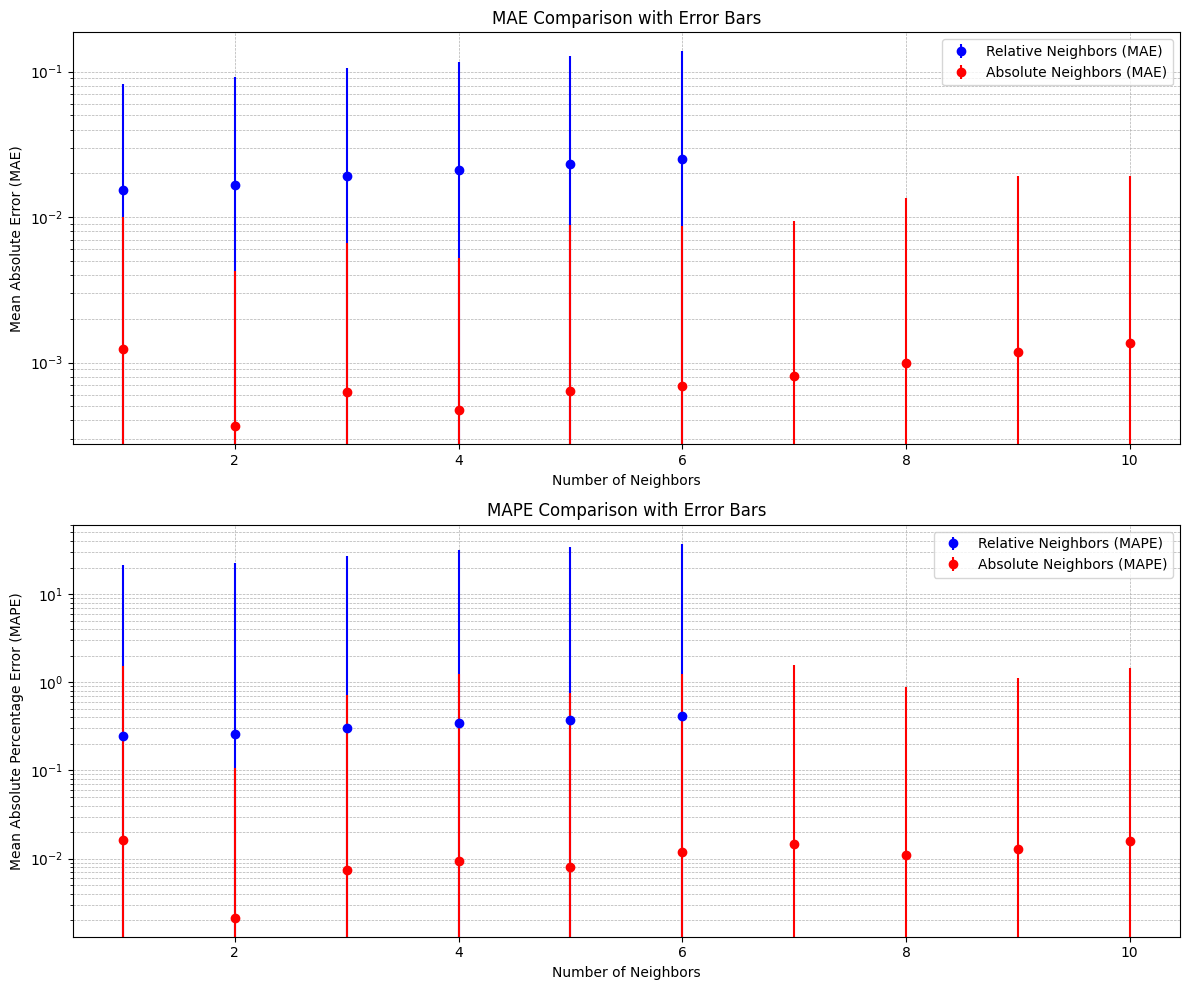

In [394]:
import matplotlib.pyplot as plt
import numpy as np

# all the same weight: 
# selecting 1 neighbor points from each w/ weights: 0.01525710 ± 0.03378282, 0.24314006 ± 10.44054365
# selecting 2 neighbor points from each w/ weights: 0.01662873 ± 0.03746533, 0.25596623 ± 11.09796579
# selecting 3 neighbor points from each w/ weights: 0.01914083 ± 0.04301705, 0.30181676 ± 13.26200437
# selecting 4 neighbor points from each w/ weights: 0.02122522 ± 0.04783783, 0.34287984 ± 15.42986321
# selecting 5 neighbor points from each w/ weights: 0.02325656 ± 0.05244324, 0.37486005 ± 16.80309680
# selecting 6 neighbor points from each w/ weights: 0.02512584 ± 0.05672616, 0.40986644 ± 18.48336027
# selecting 7 neighbor points from each w/ weights: 
# selecting 8 neighbor points from each w/ weights: 
# selecting 9 neighbor points from each w/ weights: 
# selecting 10 neighbor points from each w/ weights: 

# Data
neighbors = np.arange(1, 11)  # Neighbors from 1 to 10

# MAE and MAPE values for relative neighbors
mae_relative = [0.01525710, 0.01662873, 0.01914083, 0.02122522, 0.02325656, 0.02512584, np.nan, np.nan, np.nan, np.nan]
mae_relative_std = [0.03378282, 0.03746533, 0.04301705, 0.04783783, 0.05244324, 0.05672616, np.nan, np.nan, np.nan, np.nan]

mape_relative = [0.24314006, 0.25596623, 0.30181676, 0.34287984, 0.37486005, 0.40986644, np.nan, np.nan, np.nan, np.nan]
mape_relative_std = [10.44054365, 11.09796579, 13.26200437, 15.42986321, 16.80309680, 18.48336027, np.nan, np.nan, np.nan, np.nan]

# MAE and MAPE values for absolute neighbors
mae_absolute = [0.00123769, 0.00036879, 0.00063049, 0.00047129, 0.00063958, 0.00068672, 0.00081357, 0.00099760, 0.00117532, 0.00135558]
mae_absolute_std = [0.00440295, 0.00194119, 0.00302410, 0.00238903, 0.00407154, 0.00396896, 0.00430577, 0.00623303, 0.00894880, 0.00891612]

mape_absolute = [0.01612849, 0.00212007, 0.00750275, 0.00946985, 0.00795403, 0.01198975, 0.01453225, 0.01104227, 0.01270873, 0.01597081]
mape_absolute_std = [0.75013496, 0.05255422, 0.35828671, 0.60938218, 0.37604582, 0.61171712, 0.77444838, 0.43514810, 0.55228622, 0.72623525]

# Create subplots
fig, ax = plt.subplots(2, 1, figsize=(12, 10))

# MAE plot
ax[0].errorbar(neighbors, mae_relative, yerr=2 * np.array(mae_relative_std), fmt='o', label='Relative Neighbors (MAE)', color='blue')
ax[0].errorbar(neighbors, mae_absolute, yerr=2 * np.array(mae_absolute_std), fmt='o', label='Absolute Neighbors (MAE)', color='red')
ax[0].set_xlabel('Number of Neighbors')
ax[0].set_ylabel('Mean Absolute Error (MAE)')
ax[0].set_title('MAE Comparison with Error Bars')
ax[0].set_yscale('log')  # Logarithmic scale
ax[0].legend()
ax[0].grid(True, which='both', linestyle='--', linewidth=0.5)

# MAPE plot
ax[1].errorbar(neighbors, mape_relative, yerr=2 * np.array(mape_relative_std), fmt='o', label='Relative Neighbors (MAPE)', color='blue')
ax[1].errorbar(neighbors, mape_absolute, yerr=2 * np.array(mape_absolute_std), fmt='o', label='Absolute Neighbors (MAPE)', color='red')
ax[1].set_xlabel('Number of Neighbors')
ax[1].set_ylabel('Mean Absolute Percentage Error (MAPE)')
ax[1].set_title('MAPE Comparison with Error Bars')
ax[1].set_yscale('log')  # Logarithmic scale
ax[1].legend()
ax[1].grid(True, which='both', linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()
plt.show()


In [398]:
def extract_best_equation(csv_file_path):
    """
    Extract the best equation based on the lowest MAE from the CSV file, 
    and return the equation with its MSE, MAE, and RMSE.

    Parameters:
    - csv_file_path: str, the path to the CSV file.

    Returns:
    - tuple: (str, float, float, float), the best equation, its MSE, MAE, and RMSE.
    """
    # Load the CSV file into a DataFrame
    df = pd.read_csv(csv_file_path)

    # Find the row with the lowest MAE
    best_row = df.loc[df['MAE'].idxmin()]

    # Extract the equation and its metrics from that row
    best_equation = best_row['Equation']
    best_mse = best_row['MSE']
    best_mae = best_row['MAE']
    best_rmse = best_row['RMSE']
    
    return best_equation, best_mse, best_mae, best_rmse



csv_file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all_cr/symbolic_regression/symbolic_regression_metrics_3.csv'

best_equation, best_mse, best_mae, best_rmse = extract_best_equation(csv_file_path)

# Print the best equation with its metrics
print(f"Best Equation: {best_equation}")
print(best_mse)
print(best_mae)
print(best_rmse)

Best Equation: -x0 - 0.03286109*x0*x0 - 0.024100674*(-0.045227762*x1**2 - x1) - 1*(-0.032915827)
6.131988247821674e-06
0.0020268636699417
0.0024762851709408


In [ ]:
'''
Best Equation: -x0 + (-x0**2 + x1*sin(sin(0.8701099**(x0 - x1))) - 0.056781147)*0.032317404 + 0.032317404
2.370333704107495e-06
0.0011454518638363
0.0015395888100747
'''

In [379]:
# Define file path and target column
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'

# Get the fitted scalers and scaled DataFrame
feature_scaler, target_scaler, scaled_df = get_fitted_scaler_from_csv_both(file_path, target_col)

# Example of how to inverse transform a standardized Gibbs energy value
standardized_gibbs_energy = 1.7323417867458004

# Reverse the standardization using the target scaler
# Note: `target_scaler` expects a 2D array for inverse transformation
original_gibbs_energy = target_scaler.inverse_transform(np.array([[standardized_gibbs_energy]]))

# print("Standardized Gibbs Energy:", standardized_gibbs_energy)
# x  =  original_gibbs_energy[0, 0]


reversed_true = [target_scaler.inverse_transform(np.array([[x]]))[0,0] for x in actual]
reversed_preds = [target_scaler.inverse_transform(np.array([[x]]))[0,0] for x in all_preds]

/tmp/ipykernel_1054706/1170934002.py:55: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


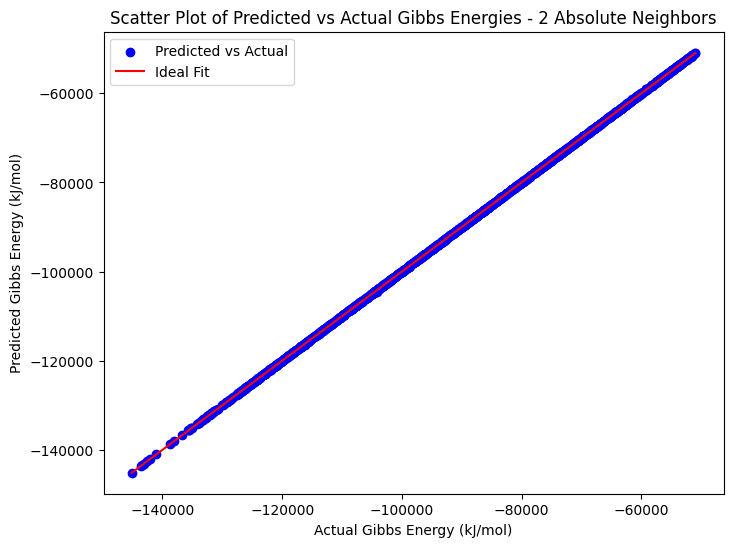

In [382]:
import matplotlib.pyplot as plt

# Example data: replace these with your actual lists
# all_preds = [/* your predicted values here */]
# actual = [/* your actual values here */]

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(reversed_true, reversed_preds, color='blue', label='Predicted vs Actual')

# Plot the ideal line (where predictions would perfectly match actual values)
plt.plot([min(reversed_true), max(reversed_true)], [min(reversed_true), max(reversed_true)], color='red', linestyle='solid', label='Ideal Fit')

# Add labels and title
plt.xlabel('Actual Gibbs Energy (kJ/mol)')
plt.ylabel('Predicted Gibbs Energy (kJ/mol)')
plt.title('Scatter Plot of Predicted vs Actual Gibbs Energies - 2 Absolute Neighbors')

# Add legend
plt.legend()

# Show the plot
plt.show()


Standardized Gibbs Energy: 1.7323417867458004
Original Gibbs Energy: -51773.0011340471


/tmp/ipykernel_1054706/1170934002.py:55: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [61]:



ref_data_points_subset = ref_data_points[:100]

x0, x1, x2, x3, x4, x5, x6, x7 = sp.symbols('x0 x1 x2 x3 x4 x5 x6 x7')
variables = [x0, x1, x2, x3, x4, x5, x6, x7]

n = 2  # Number of closest points to select per element
closest_points = get_closest_points_by_element(np.array(query_point), ref_data_points_subset, n, variables)

# Scale the selected closest points
scaled_close_points = []

print(closest_points[0])

for x in closest_points:
    x.point = np.array(clean_query_point(get_scaled(x.point, scaler)))
    scaled_close_points.append(x)

operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
3
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
6
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
9
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
12
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
operands could not be broadcast together with shapes (8,) (7,) 
15
operands could not be broadc

ValueError: 8 columns passed, passed data had 7 columns

In [60]:
test_query = remaining_data_points[700]

query_point = test_query.point
    
scaled_query = np.array(clean_point(get_scaled(query_point, scaler)))

if len(scaled_query) != len(COLUMN_TO_VAR):
    print('passing')

x0, x1, x2, x3, x4, x5, x6, x7 = sp.symbols('x0 x1 x2 x3 x4 x5 x6 x7')
filter_variables = [x0, x1, x2, x3, x4, x5, x6, x7]

symbolic_regression_equations = {
    'nb': 0.010368545 + (-x0 - 0.08986511*(-0.29881158*x1**2/1.3186632 + x1))/(0.9682296**(x0 - 0.10437104)),
    'al': 1.0387635**(x0 - (x2/1.7365125 + 1.3478543))*(0.5057765**(x2 + 1.3478543) - x0 - 1*0.46043786),
    'ti': -x0 - 0.031627774*(x0**2 - 0.73275197*x3) + 0.031627774,
    'mo': -x0 - 0.032572523*(x0**2 - 0.2002314*(x4 - 0.58379024)*(-x0 + x4 + 1.7465787)) + 0.032657675,
    'fe': -x0 + (x0**2 + (0.44672638**x5 - 1*1.324416)*(-0.08996061)*(x0 + 1.9992388))*(-0.032793973) - 1*(-0.032820575),
    'cr': -x0 + (x0*x0*1.3024131 - x6 - 1*0.117113125302202)*(-0.027785562)*0.89562523 + 0.029276866,
    # Add other elements...
}

def get_closest_points_by_element(query_point, ref_data_points, n, variables):
    """
    Find the closest `n` reference points for each element to the query point.
    
    Parameters:
    - query_point: np.array, the query point with feature values.
    - ref_data_points: a list of DataPoints objects.
    - n: int, number of closest points to return per element.
    - variables: list of sympy symbols representing the variables.
    
    Returns:
    - list of DataPoints: the closest `n` reference points for each element.
    """
    
    copy_ref_points = ref_data_points.copy()
    
    # Group reference points by their element (temp_class)
    grouped_ref_points = {}
    for point in copy_ref_points:
        element = point.temp_class  # Assuming `temp_class` stores the element name
        if element not in grouped_ref_points:
            grouped_ref_points[element] = [point]
        else:
            grouped_ref_points[element].append(point)
    
    # Find closest `n` points for each element
    selected_points = []
    counter = 0
    
    for element, points in grouped_ref_points.items():
        distances = []
        for ref_point in points:
            try:
                distance = calculate_distance(query_point, np.array(ref_point.point))
                distances.append(distance)
            except ValueError:
                print(ref_point.point)
                print(query_point)
                return
            except Exception as e:
                # print(e)
                counter += 1
                print(query_point)
                print(ref_point.point)
                raise e
    
        if counter != 0:
            print(counter)
        # Find the indices of the closest `n` points
        closest_indices = np.argsort(distances)[:n]
        
        # Append the closest points to the selected list
        selected_points.extend([points[i] for i in closest_indices])
    
    return selected_points

relevant_variables = [x0, x1, x2, x3, x4, x5, x6, x7]
closest_points = get_closest_points_by_element(np.array(query_point), ref_data_points, n=1, variables=relevant_variables)



[DataPoint(point=array([-1.41140822, -0.38435306,  0.68075616, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=2275, temp_class='al', gibbs_energy=np.float64(1.1496570137054323)),
 DataPoint(point=array([-1.24032844, -0.38435306,  5.09883628, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=2927, temp_class='al', gibbs_energy=np.float64(0.3778333312513633)),
 DataPoint(point=array([-1.02647871, -0.38435306,  3.44205623, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]), index=2689, temp_class='al', gibbs_energy=np.float64(0.2921389508497561)),
 DataPoint(point=array([-1.71079785, -0.38435306, -0.28569887, -0.40870239, -0.36739668,
        -2.42090827, -0.17921157]), index=6561, temp_class='fe', gibbs_energy=np.float64(1.7443907111985208)),
 DataPoint(point=array([-1.62525795, -0.38435306, -0.28569887, -0.40870239, -0.36739668,
         1.36997134, -0.17921157]), index=6887, temp_class='fe', gibbs_energy=np.float64(1.6687284787089802)),


In [421]:
import sympy as sp

# Define the variables
x0, x1, x2, x3, x4, x6 = sp.symbols('x0 x1 x2 x3 x4 x6')
w_i, y_i = sp.symbols('w_i y_i')

# Define the equations
f_nb = 1.03271**(x0 - 0.14734) * (-x0 + 0.02140 * x1**2 - 0.08920 * x1 + 0.01167)
f_al = 0.17100 * 0.48800**x2 - 0.9507 * x0 - 0.03460 * x0**2 + 0.01320 * x0 * x2 - 0.00120 * x2**2 - 0.41400
f_ti = -x0 + 0.24438 * (0.54978**x3 - 1.06153)
f_mo = -x0 - 0.03205 * x0**2 + 0.03205 * sp.sin(x4) + 0.04870
f_fe = (-x0) * 1.03346**x0
f_cr = -x0 - 0.03286 * x0**2 - 0.0241007 * (-0.04523 * x6**2 - x6) + 0.03292

# Calculate the gradients
grad_f_nb = sp.Matrix([sp.diff(f_nb, var) for var in [x0, x1]])
grad_f_al = sp.Matrix([sp.diff(f_al, var) for var in [x0, x2]])
grad_f_ti = sp.Matrix([sp.diff(f_ti, var) for var in [x0, x3]])
grad_f_mo = sp.Matrix([sp.diff(f_mo, var) for var in [x0, x4]])
grad_f_fe = sp.Matrix([sp.diff(f_fe, x0)])
grad_f_cr = sp.Matrix([sp.diff(f_cr, var) for var in [x0, x6]])

# Print gradients
print("Gradient of f_nb:")
sp.pprint(grad_f_nb, use_unicode=True)

print("\nGradient of f_al:")
sp.pprint(grad_f_al, use_unicode=True)

print("\nGradient of f_ti:")
sp.pprint(grad_f_ti, use_unicode=True)

print("\nGradient of f_mo:")
sp.pprint(grad_f_mo, use_unicode=True)

print("\nGradient of f_fe:")
sp.pprint(grad_f_fe, use_unicode=True)

print("\nGradient of f_cr:")
sp.pprint(grad_f_cr, use_unicode=True)

# Substitute these gradients into the final equation
# Define the expression for the predicted y
# Assuming d_{nb}, d_{al}, d_{ti}, d_{mo}, d_{fe}, d_{cr} are the direction vectors
d_nb, d_al, d_ti, d_mo, d_fe, d_cr = sp.symbols('d_nb d_al d_ti d_mo d_fe d_cr')




Gradient of f_nb:
⎡                          x₀ - 0.14734 ⎛               2                      ↪
⎢0.0321864150026518⋅1.03271            ⋅⎝-x₀ + 0.0214⋅x₁  - 0.0892⋅x₁ + 0.0116 ↪
⎢                                                                              ↪
⎢                                     x₀ - 0.14734                             ↪
⎣                              1.03271            ⋅(0.0428⋅x₁ - 0.0892)        ↪

↪  ⎞          x₀ - 0.14734⎤
↪ 7⎠ - 1.03271            ⎥
↪                         ⎥
↪                         ⎥
↪                         ⎦

Gradient of f_al:
⎡          -0.0692⋅x₀ + 0.0132⋅x₂ - 0.9507          ⎤
⎢                                                   ⎥
⎢                         x₂                        ⎥
⎣- 0.122682218305057⋅0.488   + 0.0132⋅x₀ - 0.0024⋅x₂⎦

Gradient of f_ti:
⎡             -1             ⎤
⎢                            ⎥
⎢                          x₃⎥
⎣-0.146197177800273⋅0.54978  ⎦

Gradient of f_mo:
⎡-0.0641⋅x₀ - 1 ⎤
⎢               ⎥
⎣0.

In [424]:
d_nb

d_nb

In [ ]:

# Compute Delta f for each
delta_f_nb = grad_f_nb.dot(sp.Matrix([d_nb[0], d_nb[1]]))
delta_f_al = grad_f_al.dot(sp.Matrix([d_al[0], d_al[1]]))
delta_f_ti = grad_f_ti.dot(sp.Matrix([d_ti[0], d_ti[1]]))
delta_f_mo = grad_f_mo.dot(sp.Matrix([d_mo[0], d_mo[1]]))
delta_f_fe = grad_f_fe.dot(sp.Matrix([d_fe]))
delta_f_cr = grad_f_cr.dot(sp.Matrix([d_cr[0], d_cr[1]]))

# Final prediction expression
final_expr = sp.Sum(
    w_i * (y_i +
           sp.Piecewise((delta_f_fe, 1 == 'fe'),
                        (delta_f_nb, 1 == 'nb'),
                        (delta_f_al, 1 == 'al'),
                        (delta_f_ti, 1 == 'ti'),
                        (delta_f_mo, 1 == 'mo'),
                        (delta_f_cr, 1 == 'cr')))
)

# Print final expression
print("\nFinal expression:")
sp.pprint(final_expr, use_unicode=True)


In [426]:
import sympy as sp

# Define the variables
x0, x1, x2, x3, x4, x6 = sp.symbols('x0 x1 x2 x3 x4 x6')
w_i, y_i = sp.symbols('w_i y_i')

# Define the equations
f_nb = 1.03271**(x0 - 0.14734) * (-x0 + 0.02140 * x1**2 - 0.08920 * x1 + 0.01167)
f_al = 0.17100 * 0.48800**x2 - 0.9507 * x0 - 0.03460 * x0**2 + 0.01320 * x0 * x2 - 0.00120 * x2**2 - 0.41400
f_ti = -x0 + 0.24438 * (0.54978**x3 - 1.06153)
f_mo = -x0 - 0.03205 * x0**2 + 0.03205 * sp.sin(x4) + 0.04870
f_fe = (-x0) * 1.03346**x0
f_cr = -x0 - 0.03286 * x0**2 - 0.0241007 * (-0.04523 * x6**2 - x6) + 0.03292

# Define direction vectors
d_nb, d_al, d_ti, d_mo, d_fe, d_cr = sp.symbols('d_nb d_al d_ti d_mo d_fe d_cr')

# Calculate the gradients
grad_f_nb = sp.Matrix([sp.diff(f_nb, x0), sp.diff(f_nb, x1)])
grad_f_al = sp.Matrix([sp.diff(f_al, x0), sp.diff(f_al, x2)])
grad_f_ti = sp.Matrix([sp.diff(f_ti, x0), sp.diff(f_ti, x3)])
grad_f_mo = sp.Matrix([sp.diff(f_mo, x0), sp.diff(f_mo, x4)])
grad_f_fe = sp.Matrix([sp.diff(f_fe, x0), sp.diff(f_fe, x0)])  # Iron only depends on x0
grad_f_cr = sp.Matrix([sp.diff(f_cr, x0), sp.diff(f_cr, x6)])

# Define direction vectors in a 2D space for all
dir_nb = sp.Matrix([d_nb, sp.symbols('d_nb1')])
dir_al = sp.Matrix([d_al, sp.symbols('d_al1')])
dir_ti = sp.Matrix([d_ti, sp.symbols('d_ti1')])
dir_mo = sp.Matrix([d_mo, sp.symbols('d_mo1')])
dir_fe = sp.Matrix([d_fe, d_fe])  # For f_fe, direction vector is the same
dir_cr = sp.Matrix([d_cr, sp.symbols('d_cr1')])

# Compute Delta f for each
delta_f_nb = grad_f_nb.dot(dir_nb)
delta_f_al = grad_f_al.dot(dir_al)
delta_f_ti = grad_f_ti.dot(dir_ti)
delta_f_mo = grad_f_mo.dot(dir_mo)
delta_f_fe = grad_f_fe.dot(dir_fe)
delta_f_cr = grad_f_cr.dot(dir_cr)

# Define the sum of terms for prediction
final_expr = sp.Sum(
    w_i * (y_i +
           sp.Piecewise(
               (delta_f_fe, 1 == 'fe'),
               (delta_f_nb, 1 == 'nb'),
               (delta_f_al, 1 == 'al'),
               (delta_f_ti, 1 == 'ti'),
               (delta_f_mo, 1 == 'mo'),
               (delta_f_cr, 1 == 'cr')
           )
    )
)

# Print gradients and final expression
print("Gradient of f_nb:")
sp.pprint(grad_f_nb, use_unicode=True)

print("\nGradient of f_al:")
sp.pprint(grad_f_al, use_unicode=True)

print("\nGradient of f_ti:")
sp.pprint(grad_f_ti, use_unicode=True)

print("\nGradient of f_mo:")
sp.pprint(grad_f_mo, use_unicode=True)

print("\nGradient of f_fe:")
sp.pprint(grad_f_fe, use_unicode=True)

print("\nGradient of f_cr:")
sp.pprint(grad_f_cr, use_unicode=True)

print("\nDelta f for each class:")
print(f"Delta f_nb: {delta_f_nb}")
print(f"Delta f_al: {delta_f_al}")
print(f"Delta f_ti: {delta_f_ti}")
print(f"Delta f_mo: {delta_f_mo}")
print(f"Delta f_fe: {delta_f_fe}")
print(f"Delta f_cr: {delta_f_cr}")

print("\nFinal expression:")
sp.pprint(final_expr, use_unicode=True)


Gradient of f_nb:
⎡                          x₀ - 0.14734 ⎛               2                      ↪
⎢0.0321864150026518⋅1.03271            ⋅⎝-x₀ + 0.0214⋅x₁  - 0.0892⋅x₁ + 0.0116 ↪
⎢                                                                              ↪
⎢                                     x₀ - 0.14734                             ↪
⎣                              1.03271            ⋅(0.0428⋅x₁ - 0.0892)        ↪

↪  ⎞          x₀ - 0.14734⎤
↪ 7⎠ - 1.03271            ⎥
↪                         ⎥
↪                         ⎥
↪                         ⎦

Gradient of f_al:
⎡          -0.0692⋅x₀ + 0.0132⋅x₂ - 0.9507          ⎤
⎢                                                   ⎥
⎢                         x₂                        ⎥
⎣- 0.122682218305057⋅0.488   + 0.0132⋅x₀ - 0.0024⋅x₂⎦

Gradient of f_ti:
⎡             -1             ⎤
⎢                            ⎥
⎢                          x₃⎥
⎣-0.146197177800273⋅0.54978  ⎦

Gradient of f_mo:
⎡-0.0641⋅x₀ - 1 ⎤
⎢               ⎥
⎣0.